# Tuần 6 – Error Analysis (Đỗ Xuân Bách)

**Mục tiêu:** phân tích các ca nhận diện sai của model YOLOv8n đã train ở `doxuanbach.ipynb`, tập trung vào:
1. Xe máy bị che khuất
2. Nhầm lẫn giữa xe buýt và xe tải

**Sản phẩm:**
- Thư mục `output/`: bảng số liệu (CSV), biểu đồ, ảnh các ca nhận diện sai
- File `Báo cáo tuần 6.md`: tự sinh ở cuối notebook từ số liệu thật

**Cách chạy:** mở trên Google Colab, chọn Runtime GPU, rồi *Run all*. Cần có file `best.pt` (xem mục 1.2).

In [1]:
!pip install -q ultralytics roboflow pandas


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Cấu hình
### 1.1 Tham số

In [2]:
import os, math, shutil
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from tqdm.auto import tqdm
from ultralytics import YOLO

CONF_THRES = 0.25  # ngưỡng confidence khi dự đoán
IOU_MATCH = 0.5    # IoU tối thiểu để coi là phát hiện đúng
IOU_LOC = 0.1      # IoU trong [IOU_LOC, IOU_MATCH) với đúng lớp -> lỗi lệch box

# Notebook nằm trong tuan6/; models/ và datasets/ ở thư mục gốc, dùng chung cho các tuần
ROOT = Path("..") if Path("../train.py").exists() else Path(".")
OUT_DIR = Path("output")
(OUT_DIR / "failure_cases").mkdir(parents=True, exist_ok=True)
REPORT_PATH = Path("Báo cáo tuần 6.md")

D:\ta\doxuanback\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.2 Nạp model
Notebook tìm `best.pt` theo thứ tự trong `WEIGHT_CANDIDATES`. Chạy trên máy thì dùng `models/best.pt` do `train.py` lưu ra. Chạy trên Colab thì nên copy `runs/detect/doan2_train_v8/weights/best.pt` lên Google Drive sau khi train, vì Colab sẽ xóa file khi hết phiên.

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:  # không chạy trên Colab, hoặc extension Colab của VS Code không hỗ trợ mount
    print("Không mount được Google Drive:", e)

WEIGHT_CANDIDATES = [
    str(ROOT / "models/best.pt"),  # do train.py lưu ra
    "/content/drive/MyDrive/doan2/best.pt",
    "runs/detect/doan2_train_v8/weights/best.pt",
    "best.pt",
]
WEIGHTS = next((p for p in WEIGHT_CANDIDATES if os.path.exists(p)), None)
assert WEIGHTS, "Không tìm thấy best.pt – sửa WEIGHT_CANDIDATES hoặc chạy lại phần train trong doxuanbach.ipynb"
model = YOLO(WEIGHTS)
print("Đã nạp model:", WEIGHTS)

Không mount được Google Drive: No module named 'google'
Đã nạp model: ..\models\best.pt


### 1.3 Tải dataset
API key lấy từ biến môi trường hoặc Colab Secrets (biểu tượng chìa khóa bên trái, tên `ROBOFLOW_API_KEY`). Nếu không có, notebook sẽ hỏi nhập.

In [4]:
def get_api_key():
    if os.environ.get("ROBOFLOW_API_KEY"):
        return os.environ["ROBOFLOW_API_KEY"]
    try:
        from google.colab import userdata
        return userdata.get("ROBOFLOW_API_KEY")
    except Exception:
        from getpass import getpass
        return getpass("Nhập Roboflow API key: ")

from roboflow import Roboflow

rf = Roboflow(api_key=get_api_key())
dataset = rf.workspace("project2-snimr").project("projectdoan2").version(1).download("yolov11", location=str(ROOT / "datasets/projectdoan2-1"))
DATA_DIR = Path(dataset.location)

with open(DATA_DIR / "data.yaml", encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)
names = data_cfg["names"]
if isinstance(names, dict):
    names = [names[i] for i in sorted(names)]
K = len(names)
if len(model.names) != K:
    print(f"CẢNH BÁO: model có {len(model.names)} lớp nhưng data.yaml có {K} lớp")

SPLIT = "test" if (DATA_DIR / "test" / "images").exists() else "valid"
img_dir, lbl_dir = DATA_DIR / SPLIT / "images", DATA_DIR / SPLIT / "labels"
img_paths = sorted(p for p in img_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"})
print("Các lớp:", names)
print(f"Tập đánh giá: {SPLIT} – {len(img_paths)} ảnh")

loading Roboflow workspace...


loading Roboflow project...


Các lớp: ['bus', 'car', 'motorcycle', 'truck']
Tập đánh giá: test – 18 ảnh


### 1.4 Xác định lớp xe máy / xe buýt / xe tải
Tự dò theo tên lớp. Nếu in ra sai, gán thủ công chỉ số lớp, ví dụ `MOTO = 2`.

In [5]:
def find_class(keywords):
    for i, n in enumerate(names):
        if any(k in n.lower() for k in keywords):
            return i
    return None

MOTO = find_class(["motor", "xe_may", "xe may", "xemay", "xe máy", "bike"])
BUS = find_class(["bus", "buyt", "buýt"])
TRUCK = find_class(["truck", "lorry", "xe_tai", "xe tai", "xetai", "tải"])

for label, idx in [("Xe máy", MOTO), ("Xe buýt", BUS), ("Xe tải", TRUCK)]:
    print(f"{label}: {idx} -> {names[idx] if idx is not None else 'KHÔNG TÌM THẤY'}")
assert None not in (MOTO, BUS, TRUCK), "Hãy gán thủ công MOTO / BUS / TRUCK ở cell này"

Xe máy: 2 -> motorcycle
Xe buýt: 0 -> bus
Xe tải: 3 -> truck


## 2. Hàm hỗ trợ

**Cách phân loại lỗi** (với mỗi ảnh, ghép dự đoán với nhãn thật theo thứ tự confidence giảm dần):
| Bước | Điều kiện | Nhãn thật (GT) | Dự đoán |
|---|---|---|---|
| 1 | Cùng lớp, IoU ≥ 0.5 | Đúng (TP) | TP |
| 2 | Khác lớp, IoU ≥ 0.5 | **Nhầm lớp** | FP_class |
| 3 | Cùng lớp, 0.1 ≤ IoU < 0.5 | **Lệch box** | FP_localization |
| 4 | Dự đoán còn lại đè lên GT đã ghép (IoU ≥ 0.5) | – | FP_duplicate |
| – | Không ghép được | **Bỏ sót (FN)** | FP_background |

**Đo mức che khuất:** dataset không có nhãn "bị che", nên ước lượng bằng tỉ lệ diện tích box bị các box khác đè lên. Chỉ tính các box có cạnh dưới thấp hơn trong ảnh: với camera giao thông nhìn từ trên xuống, xe nằm thấp hơn trong ảnh là xe gần camera hơn, nên có thể che xe phía sau.

In [6]:
def read_labels(lbl_path, w, h):
    boxes, clss = [], []
    if lbl_path.exists():
        for line in lbl_path.read_text().splitlines():
            parts = line.split()
            if len(parts) < 5:
                continue
            vals = list(map(float, parts[1:]))
            if len(vals) == 4:
                xc, yc, bw, bh = vals
                x1, y1, x2, y2 = xc - bw / 2, yc - bh / 2, xc + bw / 2, yc + bh / 2
            else:  # nhãn polygon -> bbox
                xs, ys = vals[0::2], vals[1::2]
                x1, y1, x2, y2 = min(xs), min(ys), max(xs), max(ys)
            boxes.append([x1 * w, y1 * h, x2 * w, y2 * h])
            clss.append(int(float(parts[0])))
    return np.array(boxes, dtype=float).reshape(-1, 4), np.array(clss, dtype=int)


def box_area(b):
    b = np.asarray(b)
    return np.clip(b[..., 2] - b[..., 0], 0, None) * np.clip(b[..., 3] - b[..., 1], 0, None)


def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    return inter / (box_area(a)[:, None] + box_area(b)[None, :] - inter + 1e-9)


def occlusion_ratios(boxes, n=30):
    # tỉ lệ diện tích mỗi box bị các box "gần camera hơn" (cạnh dưới thấp hơn) đè lên
    res = np.zeros(len(boxes))
    for i, b in enumerate(boxes):
        others = [o for j, o in enumerate(boxes)
                  if j != i and o[3] > b[3] and o[0] < b[2] and o[2] > b[0] and o[1] < b[3]]
        if not others:
            continue
        gx, gy = np.meshgrid(np.linspace(b[0], b[2], n), np.linspace(b[1], b[3], n))
        covered = np.zeros(gx.shape, bool)
        for o in others:
            covered |= (gx >= o[0]) & (gx <= o[2]) & (gy >= o[1]) & (gy <= o[3])
        res[i] = covered.mean()
    return res


def match_image(gt_boxes, gt_cls, pr_boxes, pr_cls, pr_conf):
    G, P = len(gt_boxes), len(pr_boxes)
    ious = iou_matrix(pr_boxes, gt_boxes)  # P x G
    gt_status = np.array(["FN"] * G, dtype=object)
    gt_pred, gt_pidx, gt_iou = np.full(G, -1), np.full(G, -1), np.zeros(G)
    pr_status = np.array(["FP_background"] * P, dtype=object)
    gt_used, pr_used = np.zeros(G, bool), np.zeros(P, bool)
    order = np.argsort(-pr_conf)

    def stage(same_cls, lo, hi, gt_label, pr_label):
        for p in order:
            if pr_used[p]:
                continue
            best_g, best_iou = -1, lo
            for g in range(G):
                if gt_used[g] or (gt_cls[g] == pr_cls[p]) != same_cls:
                    continue
                if best_iou <= ious[p, g] < hi:
                    best_g, best_iou = g, ious[p, g]
            if best_g >= 0:
                gt_used[best_g] = pr_used[p] = True
                gt_status[best_g], pr_status[p] = gt_label, pr_label
                gt_pred[best_g], gt_pidx[best_g], gt_iou[best_g] = pr_cls[p], p, ious[p, best_g]

    stage(True, IOU_MATCH, 1.01, "TP", "TP")
    stage(False, IOU_MATCH, 1.01, "Confused", "FP_class")
    stage(True, IOU_LOC, IOU_MATCH, "Localization", "FP_localization")
    for p in range(P):
        if not pr_used[p] and G and ious[p].max() >= IOU_MATCH:
            pr_status[p] = "FP_duplicate"
    return gt_status, gt_pred, gt_pidx, gt_iou, pr_status

## 3. Chạy dự đoán và ghép với nhãn thật

In [7]:
gt_records, pr_records = [], []
for img_path in tqdm(img_paths):
    res = model.predict(str(img_path), conf=CONF_THRES, verbose=False)[0]
    h, w = res.orig_shape
    gt_boxes, gt_cls = read_labels(lbl_dir / (img_path.stem + ".txt"), w, h)
    pr_boxes = res.boxes.xyxy.cpu().numpy()
    pr_cls = res.boxes.cls.cpu().numpy().astype(int)
    pr_conf = res.boxes.conf.cpu().numpy()

    occ = occlusion_ratios(gt_boxes)
    gt_status, gt_pred, gt_pidx, gt_iou, pr_status = match_image(gt_boxes, gt_cls, pr_boxes, pr_cls, pr_conf)

    for g in range(len(gt_boxes)):
        p = gt_pidx[g]
        gt_records.append(dict(
            image=str(img_path), cls=int(gt_cls[g]), cls_name=names[gt_cls[g]],
            box=gt_boxes[g].tolist(), area_ratio=float(box_area(gt_boxes[g]) / (w * h)),
            occlusion=float(occ[g]), status=gt_status[g],
            pred_cls=int(gt_pred[g]), pred_name=names[gt_pred[g]] if gt_pred[g] >= 0 else "",
            pred_box=pr_boxes[p].tolist() if p >= 0 else None,
            pred_conf=float(pr_conf[p]) if p >= 0 else np.nan, iou=float(gt_iou[g]),
        ))
    for p in range(len(pr_boxes)):
        pr_records.append(dict(
            image=str(img_path), cls=int(pr_cls[p]), cls_name=names[pr_cls[p]],
            conf=float(pr_conf[p]), box=pr_boxes[p].tolist(), status=pr_status[p],
        ))

gt_df, pr_df = pd.DataFrame(gt_records), pd.DataFrame(pr_records)
gt_df.to_csv(OUT_DIR / "gt_matches.csv", index=False)
pr_df.to_csv(OUT_DIR / "predictions.csv", index=False)
print(f"{len(gt_df)} đối tượng thật, {len(pr_df)} dự đoán")

  0%|          | 0/18 [00:00<?, ?it/s]

  6%|▌         | 1/18 [00:03<00:55,  3.25s/it]

 33%|███▎      | 6/18 [00:03<00:05,  2.39it/s]

 72%|███████▏  | 13/18 [00:03<00:00,  6.15it/s]

100%|██████████| 18/18 [00:03<00:00,  5.05it/s]

628 đối tượng thật, 676 dự đoán


## 4. Thống kê lỗi theo lớp

In [8]:
STATUS_VI = {"TP": "Đúng (TP)", "FN": "Bỏ sót (FN)", "Confused": "Nhầm lớp", "Localization": "Lệch box"}
FP_VI = {"FP_background": "Báo nhầm nền", "FP_class": "Sai lớp", "FP_localization": "Lệch box", "FP_duplicate": "Trùng lặp"}

err_tbl = (pd.crosstab(gt_df.cls_name, gt_df.status)
           .reindex(index=names, columns=list(STATUS_VI), fill_value=0))
err_tbl["Tổng"] = err_tbl.sum(axis=1)
err_tbl["Recall"] = (err_tbl["TP"] / err_tbl["Tổng"].replace(0, np.nan)).round(3)
err_tbl = err_tbl.rename(columns=STATUS_VI)
err_tbl.index.name = "Lớp"

fp_tbl = (pd.crosstab(pr_df.cls_name, pr_df.status)
          .reindex(index=names, columns=["TP"] + list(FP_VI), fill_value=0))
fp_tbl["Tổng dự đoán"] = fp_tbl.sum(axis=1)
fp_tbl["Precision"] = (fp_tbl["TP"] / fp_tbl["Tổng dự đoán"].replace(0, np.nan)).round(3)
fp_tbl = fp_tbl.rename(columns={"TP": "Đúng (TP)", **FP_VI})
fp_tbl.index.name = "Lớp dự đoán"

# Recall theo kích thước box (so với diện tích ảnh): nhỏ < 0.25%, vừa < 2%, lớn còn lại
SIZE_LABELS = ["Nhỏ", "Vừa", "Lớn"]
gt_df["kich_thuoc"] = pd.cut(gt_df.area_ratio, [0, 0.0025, 0.02, 1.0], labels=SIZE_LABELS, include_lowest=True)
size_tbl = (gt_df.assign(dung=gt_df.status == "TP")
            .pivot_table(index="cls_name", columns="kich_thuoc", values="dung", aggfunc="mean", observed=False)
            .reindex(index=names, columns=SIZE_LABELS).round(3))
size_tbl.index.name = "Lớp (recall)"

for t, f in [(err_tbl, "loi_theo_lop.csv"), (fp_tbl, "du_doan_sai_theo_lop.csv"), (size_tbl, "recall_theo_kich_thuoc.csv")]:
    t.to_csv(OUT_DIR / f)
display(err_tbl, fp_tbl, size_tbl)

status,Đúng (TP),Bỏ sót (FN),Nhầm lớp,Lệch box,Tổng,Recall
Lớp,,,,,,
bus,9,6,4,0,19,0.474
car,145,16,5,6,172,0.843
motorcycle,315,49,1,24,389,0.810
truck,29,9,7,3,48,0.604


status,Đúng (TP),Báo nhầm nền,Sai lớp,Lệch box,Trùng lặp,Tổng dự đoán,Precision
Lớp dự đoán,,,,,,,
bus,9,1,0,0,3,13,0.692
car,145,8,9,6,6,174,0.833
motorcycle,315,55,0,24,43,437,0.721
truck,29,6,8,3,6,52,0.558


kich_thuoc,Nhỏ,Vừa,Lớn
Lớp (recall),,,
bus,0.000,0.375,0.6
car,0.675,0.976,1.0
motorcycle,0.708,0.957,0.0
truck,0.318,0.846,NaN


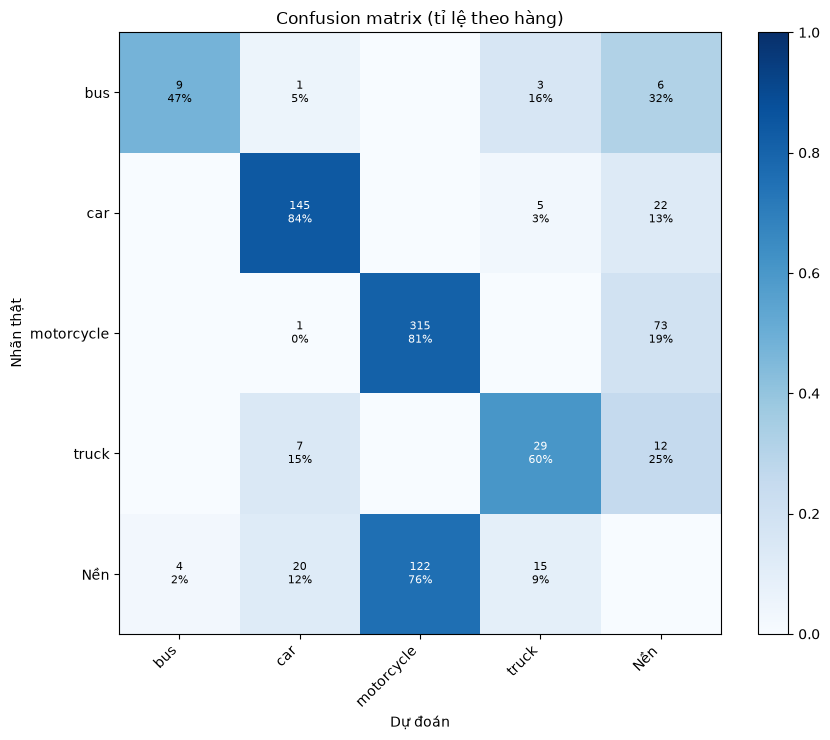

In [9]:
# Confusion matrix: hàng = nhãn thật, cột = dự đoán, chỉ số K = "Nền" (không có đối tượng)
cm = np.zeros((K + 1, K + 1), int)
for r in gt_df.itertuples():
    cm[r.cls, r.pred_cls if r.status in ("TP", "Confused") else K] += 1
for r in pr_df[pr_df.status.isin(["FP_background", "FP_localization", "FP_duplicate"])].itertuples():
    cm[K, r.cls] += 1

labels = names + ["Nền"]
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(1.2 * K + 4, 1.0 * K + 3.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(K + 1):
    for j in range(K + 1):
        if cm[i, j]:
            ax.text(j, i, f"{cm[i, j]}\n{cm_norm[i, j]:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xticks(range(K + 1), labels, rotation=45, ha="right")
ax.set_yticks(range(K + 1), labels)
ax.set_xlabel("Dự đoán")
ax.set_ylabel("Nhãn thật")
ax.set_title("Confusion matrix (tỉ lệ theo hàng)")
fig.colorbar(im, fraction=0.046)
fig.tight_layout()
fig.savefig(OUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## 5. Xe máy bị che khuất

status,Đúng (TP),Bỏ sót (FN),Nhầm lớp,Lệch box,Tổng,Recall
Mức che khuất,,,,,,
Không che (<10%),234,22,1,9,266,0.880
Che một phần (10–40%),57,13,0,6,76,0.750
Che nhiều (>40%),24,14,0,9,47,0.511


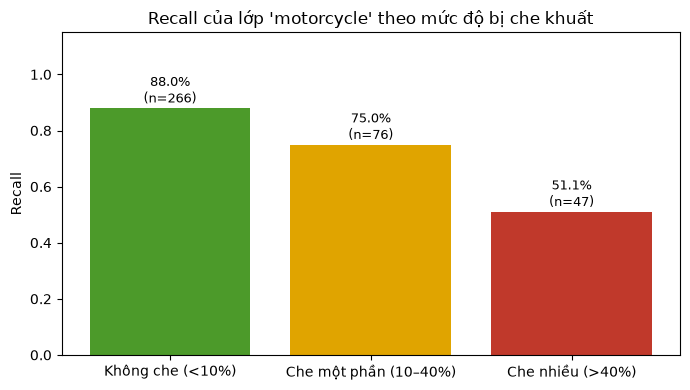

In [10]:
OCC_LABELS = ["Không che (<10%)", "Che một phần (10–40%)", "Che nhiều (>40%)"]
moto = gt_df[gt_df.cls == MOTO].copy()
moto["muc_che"] = pd.cut(moto.occlusion, [0, 0.1, 0.4, 1.01], labels=OCC_LABELS, right=False)

occ_tbl = (pd.crosstab(moto.muc_che, moto.status, dropna=False)
           .reindex(index=OCC_LABELS, columns=list(STATUS_VI), fill_value=0))
occ_tbl["Tổng"] = occ_tbl.sum(axis=1)
occ_tbl["Recall"] = (occ_tbl["TP"] / occ_tbl["Tổng"].replace(0, np.nan)).round(3)
occ_tbl = occ_tbl.rename(columns=STATUS_VI)
occ_tbl.index.name = "Mức che khuất"
occ_tbl.to_csv(OUT_DIR / "xe_may_che_khuat.csv")
display(occ_tbl)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(OCC_LABELS, occ_tbl["Recall"].fillna(0), color=["#4c9a2a", "#e0a400", "#c0392b"])
for bar, n, r in zip(bars, occ_tbl["Tổng"], occ_tbl["Recall"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02,
            f"{r:.1%}\n(n={n})" if n else "n=0", ha="center", fontsize=9)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Recall")
ax.set_title(f"Recall của lớp '{names[MOTO]}' theo mức độ bị che khuất")
fig.tight_layout()
fig.savefig(OUT_DIR / "xe_may_recall_che_khuat.png", dpi=150)
plt.show()

## 6. Nhầm lẫn xe buýt – xe tải

,Tổng,Đúng,Nhầm sang lớp kia,Nhầm sang lớp khác,Bỏ sót / lệch box,Tỉ lệ nhầm buýt↔tải
Lớp thật,,,,,,
bus,19,9,3,1,6,0.158
truck,48,29,0,7,12,0.000


,Số box (train),Số box (test)
Lớp,,
bus,91,19
car,1444,172
motorcycle,2711,389
truck,366,48


,Số lượng,Diện tích box trung vị (% ảnh),Confidence trung bình
Kết quả,,,
Lỗi khác,26,0.19,0.411
Nhầm buýt↔tải,3,0.55,0.381
Đúng,38,0.49,0.644


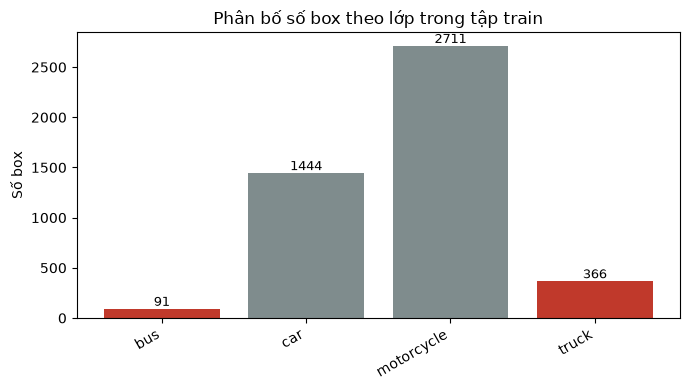

In [11]:
def n_status(c, status):
    return int(((gt_df.cls == c) & (gt_df.status == status)).sum())

def n_confused(a, b):
    return int(((gt_df.cls == a) & (gt_df.status == "Confused") & (gt_df.pred_cls == b)).sum())

rows = []
for a, b in [(BUS, TRUCK), (TRUCK, BUS)]:
    total = int((gt_df.cls == a).sum())
    rows.append({
        "Lớp thật": names[a], "Tổng": total, "Đúng": n_status(a, "TP"),
        f"Nhầm sang lớp kia": n_confused(a, b),
        "Nhầm sang lớp khác": n_status(a, "Confused") - n_confused(a, b),
        "Bỏ sót / lệch box": n_status(a, "FN") + n_status(a, "Localization"),
    })
bt_tbl = pd.DataFrame(rows).set_index("Lớp thật")
bt_tbl["Tỉ lệ nhầm buýt↔tải"] = (bt_tbl["Nhầm sang lớp kia"] / bt_tbl["Tổng"].replace(0, np.nan)).round(3)
bt_tbl.to_csv(OUT_DIR / "nham_buyt_tai.csv")

# Phân bố dữ liệu train: kiểm tra mất cân bằng lớp
def count_classes(split):
    cnt = np.zeros(K, int)
    for f in (DATA_DIR / split / "labels").glob("*.txt"):
        for line in f.read_text().splitlines():
            if line.strip():
                cnt[int(float(line.split()[0]))] += 1
    return cnt

train_counts = count_classes("train")
dist_tbl = pd.DataFrame({"Số box (train)": train_counts,
                         f"Số box ({SPLIT})": [int((gt_df.cls == i).sum()) for i in range(K)]},
                        index=pd.Index(names, name="Lớp"))
dist_tbl.to_csv(OUT_DIR / "phan_bo_lop.csv")

# Các ca nhầm có phải là xe nhỏ / ở xa không?
bt_df = gt_df[gt_df.cls.isin([BUS, TRUCK])].copy()
bt_df["ket_qua"] = np.select(
    [bt_df.status == "TP", (bt_df.status == "Confused") & bt_df.pred_cls.isin([BUS, TRUCK])],
    ["Đúng", "Nhầm buýt↔tải"], "Lỗi khác")
bt_size_tbl = bt_df.rename(columns={"ket_qua": "Kết quả"}).groupby("Kết quả").agg(
    **{"Số lượng": ("image", "size"),
       "Diện tích box trung vị (% ảnh)": ("area_ratio", lambda s: round(s.median() * 100, 2)),
       "Confidence trung bình": ("pred_conf", lambda s: round(s.mean(), 3))})
display(bt_tbl, dist_tbl, bt_size_tbl)

fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#c0392b" if i in (BUS, TRUCK) else "#7f8c8d" for i in range(K)]
ax.bar(names, train_counts, color=colors)
for i, v in enumerate(train_counts):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Số box")
ax.set_title("Phân bố số box theo lớp trong tập train")
plt.xticks(rotation=30, ha="right")
fig.tight_layout()
fig.savefig(OUT_DIR / "phan_bo_lop_train.png", dpi=150)
plt.show()

## 7. Ảnh các ca nhận diện sai (Failure Cases)
Khung **xanh** là nhãn thật, khung **đỏ** là dự đoán của model. Khi xem ảnh, hãy để ý cả các ca **gán nhãn sai trong dataset**: nhiều "lỗi" thực ra là do nhãn sai.

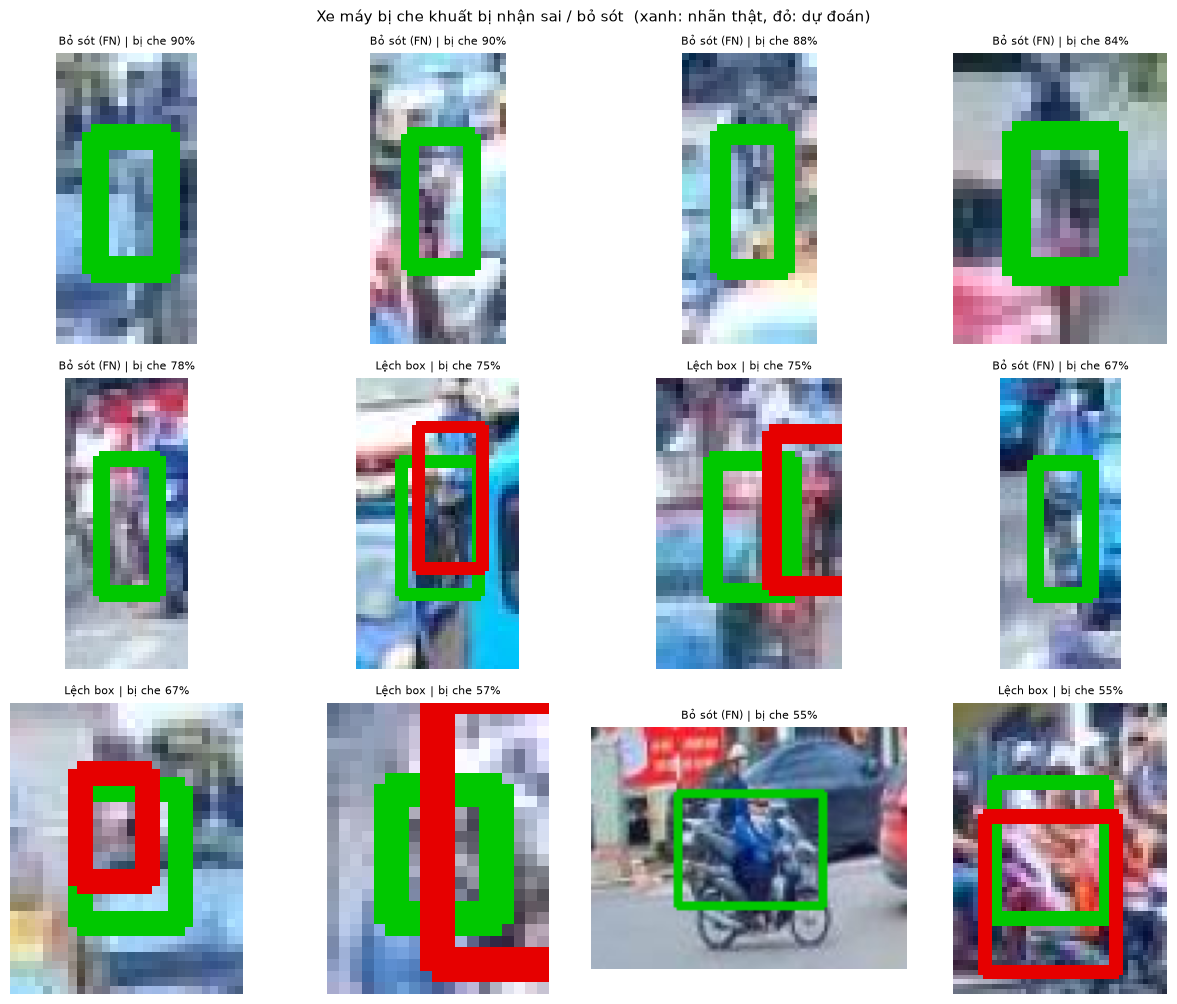

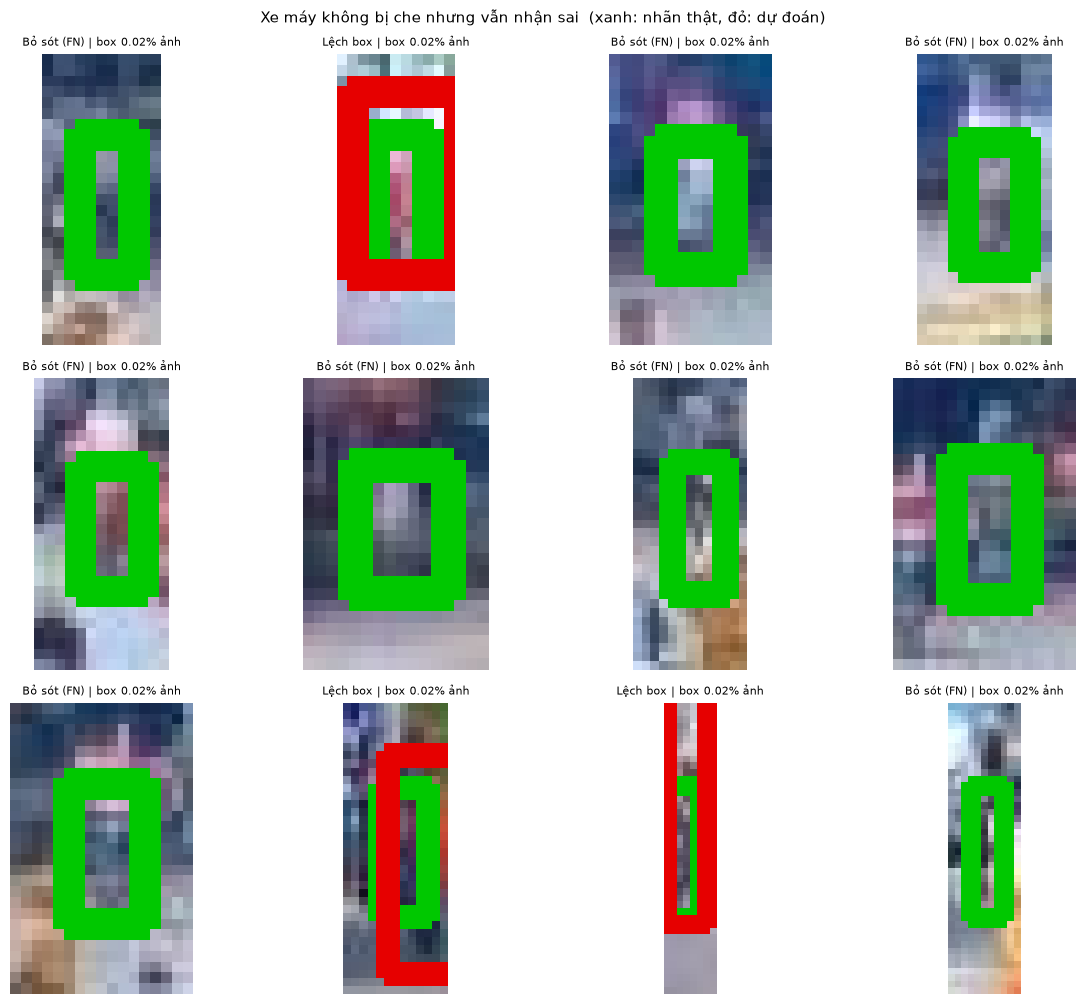

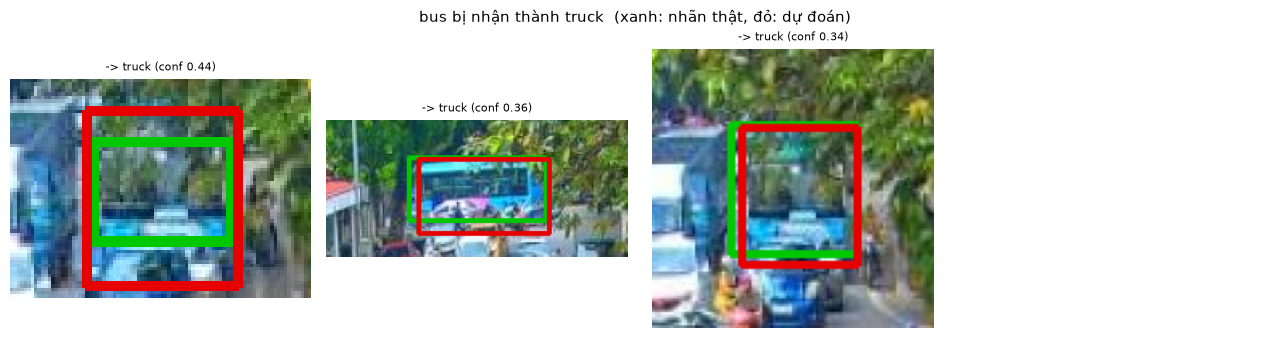

Không có ca nào: truck bị nhận thành bus


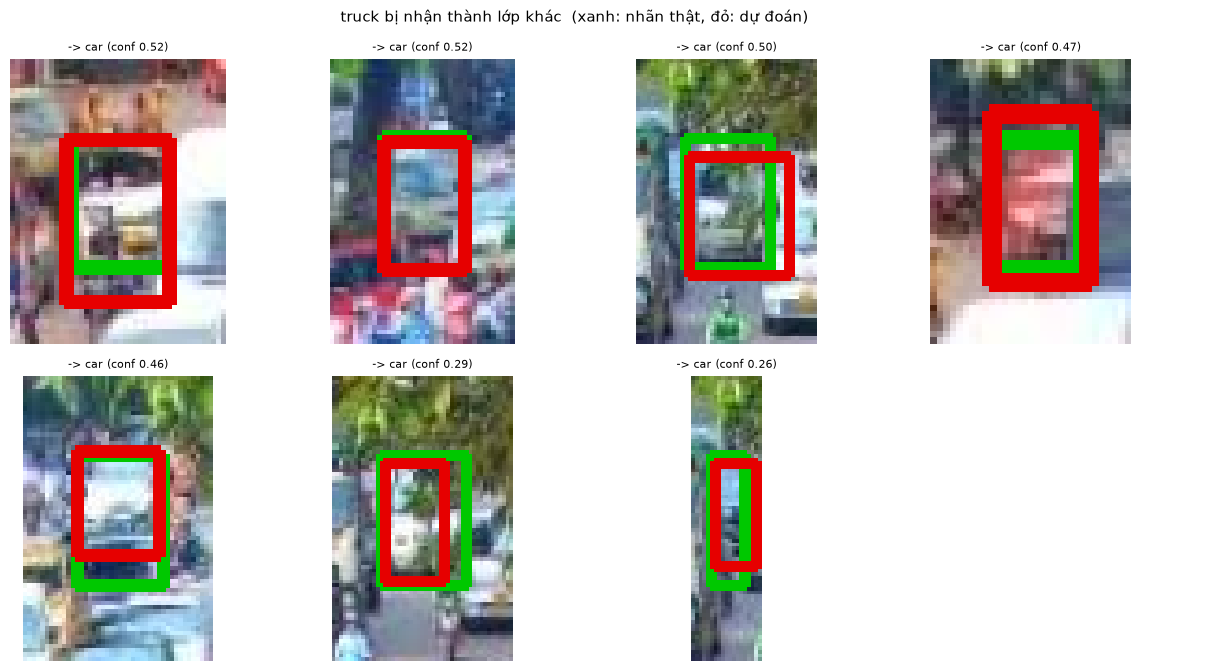

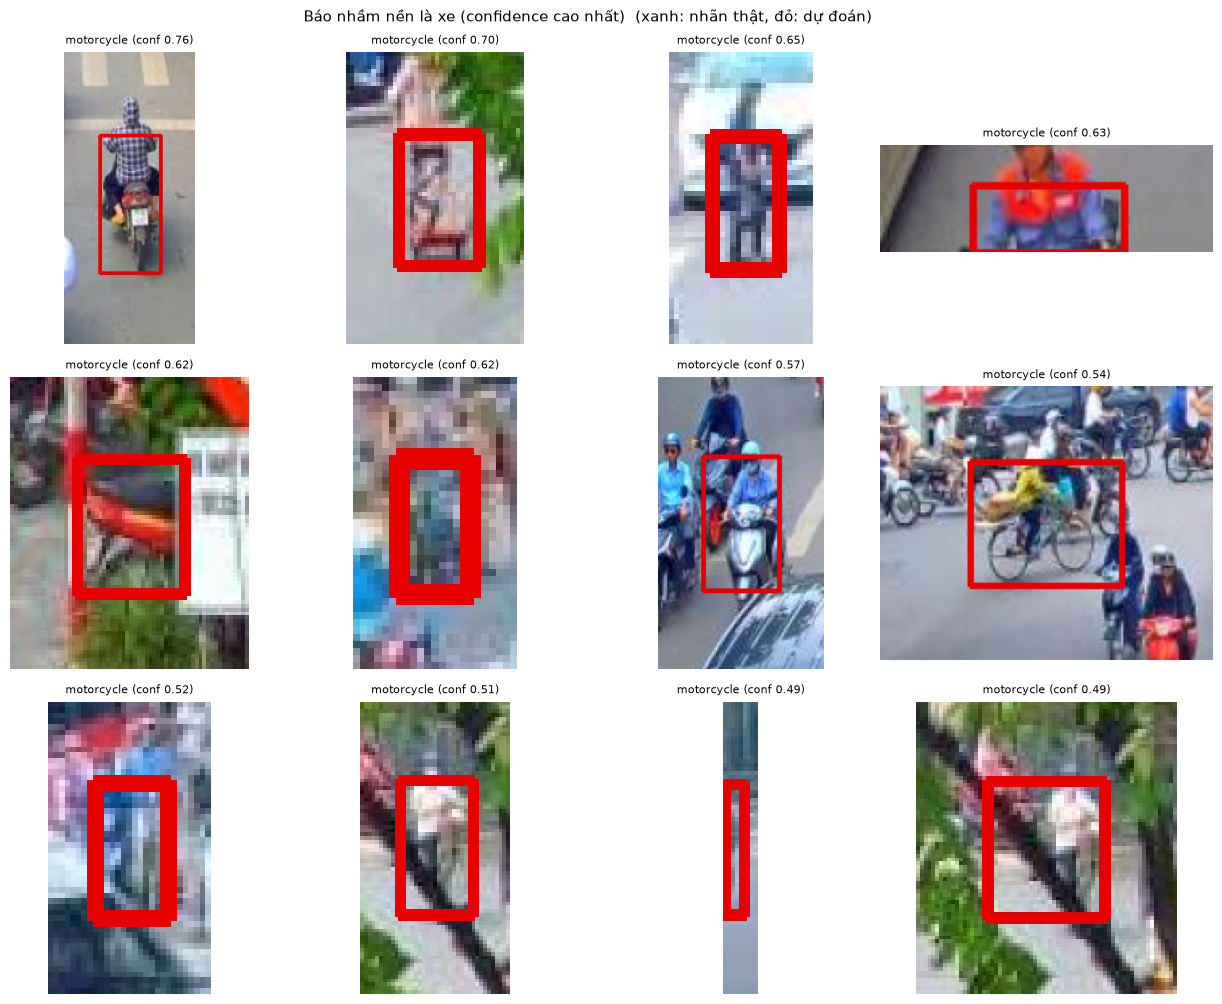

In [12]:
def draw_crop(img_path, focus, gt=None, pred=None, pad=0.6):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    t = max(2, round(max(h, w) / 400))
    for box, color in [(gt, (0, 200, 0)), (pred, (230, 0, 0))]:
        if box is not None:
            cv2.rectangle(img, (int(box[0]), int(box[1])), (int(box[2]), int(box[3])), color, t)
    x1, y1, x2, y2 = focus
    bw, bh = x2 - x1, y2 - y1
    return img[int(max(0, y1 - pad * bh)):int(min(h, y2 + pad * bh)),
               int(max(0, x1 - pad * bw)):int(min(w, x2 + pad * bw))]


def save_gallery(items, title, fname, max_n=12, cols=4):
    items = items[:max_n]
    if not items:
        print("Không có ca nào:", title)
        return None
    rows = math.ceil(len(items) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.2, rows * 3.4), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, it in zip(axes.flat, items):
        ax.imshow(draw_crop(it["image"], it["focus"], it.get("gt"), it.get("pred")))
        ax.set_title(it["caption"], fontsize=8)
    fig.suptitle(f"{title}  (xanh: nhãn thật, đỏ: dự đoán)", fontsize=11)
    fig.tight_layout()
    path = OUT_DIR / "failure_cases" / fname
    fig.savefig(path, dpi=130)
    plt.show()
    return path


def gt_items(df, caption):
    return [dict(image=r.image, focus=r.box, gt=r.box, pred=r.pred_box, caption=caption(r))
            for r in df.itertuples()]


moto_err = moto[moto.status != "TP"]
galleries = {
    "moto_occluded": save_gallery(
        gt_items(moto_err[moto_err.occlusion >= 0.1].sort_values("occlusion", ascending=False),
                 lambda r: f"{STATUS_VI[r.status]} | bị che {r.occlusion:.0%}"),
        "Xe máy bị che khuất bị nhận sai / bỏ sót", "xe_may_bi_che.png"),
    "moto_other": save_gallery(
        gt_items(moto_err[moto_err.occlusion < 0.1].sort_values("area_ratio"),
                 lambda r: f"{STATUS_VI[r.status]} | box {r.area_ratio:.2%} ảnh"),
        "Xe máy không bị che nhưng vẫn nhận sai", "xe_may_loi_khac.png"),
    "bus2truck": save_gallery(
        gt_items(gt_df[(gt_df.cls == BUS) & (gt_df.pred_cls == TRUCK) & (gt_df.status == "Confused")]
                 .sort_values("pred_conf", ascending=False),
                 lambda r: f"-> {r.pred_name} (conf {r.pred_conf:.2f})"),
        f"{names[BUS]} bị nhận thành {names[TRUCK]}", "buyt_thanh_tai.png"),
    "truck2bus": save_gallery(
        gt_items(gt_df[(gt_df.cls == TRUCK) & (gt_df.pred_cls == BUS) & (gt_df.status == "Confused")]
                 .sort_values("pred_conf", ascending=False),
                 lambda r: f"-> {r.pred_name} (conf {r.pred_conf:.2f})"),
        f"{names[TRUCK]} bị nhận thành {names[BUS]}", "tai_thanh_buyt.png"),
    "truck_other": save_gallery(
        gt_items(gt_df[(gt_df.cls == TRUCK) & (gt_df.status == "Confused") & (gt_df.pred_cls != BUS)]
                 .sort_values("pred_conf", ascending=False),
                 lambda r: f"-> {r.pred_name} (conf {r.pred_conf:.2f})"),
        f"{names[TRUCK]} bị nhận thành lớp khác", "tai_thanh_lop_khac.png"),
    "fp_background": save_gallery(
        [dict(image=r.image, focus=r.box, pred=r.box, caption=f"{r.cls_name} (conf {r.conf:.2f})")
         for r in pr_df[pr_df.status == "FP_background"].sort_values("conf", ascending=False).itertuples()],
        "Báo nhầm nền là xe (confidence cao nhất)", "bao_nham_nen.png"),
}

## 8. Nhận xét từ việc xem ảnh failure case
Phần này **viết tay** sau khi xem các ảnh ở mục 7, vì số liệu không cho biết lỗi trông như thế nào. Các nhận xét dưới đây áp dụng cho model `models/best.pt` train ngày 01/11/2026. **Nếu train lại model, hãy xem lại ảnh ở mục 7 và sửa các nhận xét cho khớp.**

In [13]:
QUAN_SAT = {
    "moto": [
        "Phần lớn xe máy bị che nhiều mà bị bỏ sót là đối tượng rất nhỏ ở xa camera (chỉ vài chục pixel), "
        "phần xe gần như bị xe phía trước che hết, chỉ còn thấy đầu hoặc thân người lái. Ngay cả khi nhìn bằng mắt "
        "cũng khó nhận ra đó là xe máy.",
        "Ở các ca lệch box, model chỉ khoanh được phần nhìn thấy (người lái hoặc nửa trên của xe), hoặc khoanh dính "
        "sang xe bên cạnh, nên IoU với nhãn thật thấp hơn 0.5.",
        "Vẫn có ca xe máy nhìn rõ nhưng bị bỏ sót khi đứng sát ô tô. Điều này phù hợp với giả thuyết bước NMS đã xóa "
        "nhầm box của các xe đứng sát nhau.",
    ],
    "bus_truck": [
        "Cả 3 ca xe buýt bị nhận thành xe tải đều là xe buýt ở xa, bị cây hoặc xe khác che một phần, chỉ thấy phần "
        "đầu hoặc đuôi xe. Các dự đoán sai đều có confidence thấp (0.34–0.44).",
        "Nhầm lẫn chính của lớp xe tải là bị nhận thành ô tô (7 ca), không phải thành xe buýt. Các ca này đều là xe "
        "tải nhìn thẳng từ phía trước, ở xa (box chỉ chiếm khoảng 0.1–0.2% diện tích ảnh). Ở góc nhìn đó chỉ thấy "
        "cabin, rất giống ô tô hoặc xe van. Confidence của các dự đoán sai thấp (0.26–0.52).",
    ],
    "fp": [
        "Nhiều ca \"báo nhầm nền\" thực ra là xe máy thật nhưng dataset không gán nhãn (ví dụ xe máy chở người nhìn "
        "từ trên xuống, xe tay ga trong dòng xe đông). Như vậy precision thực tế của lớp xe máy cao hơn con số đo "
        "được, và dataset cần được rà soát để bổ sung nhãn còn thiếu.",
        "Một số ca là lỗi thật: xe đạp bị nhận thành xe máy (dataset không có lớp xe đạp), người đi bộ hoặc người "
        "đứng bên đường bị nhận thành xe máy.",
    ],
    "train": "Model dừng sớm ở epoch 40/400 (kết quả tốt nhất ở epoch 30) do patience=10.",
    # Lưu ý về lần train và cách tái lập kết quả (đưa vào mục "Hạn chế và lưu ý" của báo cáo)
    "luu_y": [
        "Model được train lại trên máy cá nhân (GPU NVIDIA RTX 3050 Laptop 4GB) bằng train.py, cùng cấu hình với "
        "notebook gốc doxuanbach.ipynb (YOLOv8n, 400 epoch, patience=10, ảnh 640, batch 16). Model dừng ở epoch 40, "
        "tốt nhất ở epoch 30, mAP@0.5 trên tập val đạt 0.777. Vì train lại nên số liệu có thể hơi khác so với lần "
        "train trước trên Colab.",
        "Model được lưu tại models/best.pt và dùng chung cho các tuần sau, không cần train lại. Kết quả train gốc "
        "(biểu đồ loss, results.csv) nằm ở runs/detect/runs/detect/doan2_train_v8/ (Ultralytics bản mới tự thêm "
        "runs/detect vào trước đường dẫn).",
        "Phần \"Quan sát từ ảnh\" ở các mục 4–6 được viết tay sau khi xem ảnh failure case của model này. Nếu train "
        "lại model, cần xem lại ảnh và cập nhật phần này. Các số liệu và nhận xét còn lại được tính tự động.",
        "Precision và Recall trong báo cáo này tính ở ngưỡng confidence cố định 0.25, nên sẽ khác với Precision/"
        "Recall trong báo cáo tuần 7 (lấy tại ngưỡng cho F1 cao nhất).",
        "Cách chạy lại: mở tuan6/tuần 6.ipynb trong VS Code, chọn kernel .venv của dự án rồi Run all (khoảng 1–2 "
        "phút). API key Roboflow không được lưu trong file; nếu cần tải lại dataset, đặt biến môi trường "
        "ROBOFLOW_API_KEY hoặc nhập khi notebook hỏi.",
    ],
}

## 9. Sinh báo cáo Markdown

In [14]:
class MdReport:
    # Báo cáo Markdown: các mục, đoạn văn, bảng, ảnh được ghép thành từng dòng rồi ghi ra file .md
    def __init__(self):
        self.lines = []

    def add_heading(self, text, level=1):
        self.lines += ["#" * (level + 1) + " " + text, ""]

    def add_paragraph(self, text="", bold=False):
        self.lines += [f"**{text}**" if bold else text, ""]

    def save(self, path):
        Path(path).write_text("\n".join(self.lines), encoding="utf-8")


def pct(x):
    return "–" if x is None or pd.isna(x) else f"{x:.1%}"


def fmt(v):
    if isinstance(v, (float, np.floating)):
        return "–" if np.isnan(v) else f"{v:.3f}".rstrip("0").rstrip(".")
    return str(v)


counter = {"Bảng": 0, "Hình": 0}


def caption(kind, text):
    counter[kind] += 1
    return f"{kind} {counter[kind]}. {text}"


def add_table(doc, df, title):
    doc.add_paragraph(caption("Bảng", title), bold=True)
    data = df.reset_index()
    doc.lines.append("| " + " | ".join(str(c) for c in data.columns) + " |")
    doc.lines.append("|" + "|".join(["---"] * len(data.columns)) + "|")
    for row in data.itertuples(index=False):
        doc.lines.append("| " + " | ".join(fmt(v).replace("|", "\\|") for v in row) + " |")
    doc.lines.append("")


def add_image(doc, path, title):
    # đường dẫn ảnh tương đối so với file báo cáo (cùng thư mục với notebook)
    if path is None or not Path(path).exists():
        return
    cap = caption("Hình", title)
    doc.lines += [f"![{cap}]({Path(path).as_posix()})", "", f"*{cap}*", ""]


def bullets(doc, items):
    doc.lines += [f"- {s}" for s in items] + [""]


def observations(doc, items):
    if items:
        doc.add_paragraph("Quan sát từ ảnh:", bold=True)
        bullets(doc, items)


# ---------- số liệu cho phần nhận xét ----------
overall_recall = (gt_df.status == "TP").mean()
overall_prec = (pr_df.status == "TP").mean() if len(pr_df) else np.nan
weakest = err_tbl["Recall"].idxmin()
err_share = gt_df[gt_df.status != "TP"].status.value_counts(normalize=True)

occ_recall = occ_tbl["Recall"]
r_none, r_heavy = occ_recall.iloc[0], occ_recall.iloc[-1]
moto_occ_err_share = (moto_err.occlusion >= 0.1).mean() if len(moto_err) else np.nan

n_bus, n_truck = int(bt_tbl.loc[names[BUS], "Tổng"]), int(bt_tbl.loc[names[TRUCK], "Tổng"])
b2t, t2b = n_confused(BUS, TRUCK), n_confused(TRUCK, BUS)
tr_bus, tr_truck = int(train_counts[BUS]), int(train_counts[TRUCK])
truck_conf_to = gt_df[(gt_df.cls == TRUCK) & (gt_df.status == "Confused")].pred_name.value_counts()

doc = MdReport()

doc.add_heading("BÁO CÁO TUẦN 6 – PHÂN TÍCH CÁC CA NHẬN DIỆN SAI (ERROR ANALYSIS)", level=0)
bullets(doc, [
    "Người thực hiện: Đỗ Xuân Bách",
    f"Ngày: {datetime.now():%d/%m/%Y}",
    f"Model: YOLOv8n ({Path(WEIGHTS).name}), ngưỡng confidence {CONF_THRES}",
    f"Dữ liệu đánh giá: Roboflow projectdoan2 v1, tập {SPLIT} gồm {len(img_paths)} ảnh, "
    f"{len(gt_df)} đối tượng, {K} lớp ({', '.join(names)})",
])

doc.add_heading("1. Mục tiêu", level=1)
doc.add_paragraph(
    "Tìm hiểu model đang sai ở đâu và vì sao, để định hướng cải thiện ở các tuần sau. Báo cáo tập trung vào hai "
    "nhóm lỗi chính: (1) xe máy bị che khuất trong cảnh giao thông đông đúc, (2) nhầm lẫn giữa xe buýt và xe tải.")

doc.add_heading("2. Phương pháp", level=1)
doc.add_paragraph(
    f"Chạy model trên toàn bộ tập {SPLIT}, sau đó ghép từng dự đoán với nhãn thật theo thứ tự confidence giảm dần "
    "và xếp mỗi đối tượng vào một trong các nhóm sau:")
bullets(doc, [
    f"Đúng (TP): cùng lớp, IoU ≥ {IOU_MATCH}.",
    f"Nhầm lớp: box đúng vị trí (IoU ≥ {IOU_MATCH}) nhưng sai lớp.",
    f"Lệch box: đúng lớp nhưng {IOU_LOC} ≤ IoU < {IOU_MATCH}.",
    "Bỏ sót (FN): không có dự đoán nào khớp.",
    "Với các dự đoán thừa: báo nhầm nền (không có xe), trùng lặp (hai box cho cùng một xe).",
])
doc.add_paragraph(
    "Mức độ che khuất: dataset không có nhãn che khuất, nên được ước lượng bằng tỉ lệ diện tích box bị các box khác "
    "đè lên. Chỉ tính các box có cạnh dưới thấp hơn trong ảnh (tức gần camera hơn). Chia thành 3 mức: "
    "không che (<10%), che một phần (10–40%), che nhiều (>40%).")
doc.add_paragraph(
    "Sau khi có số liệu, các ảnh failure case của từng nhóm lỗi được xem trực tiếp để tìm nguyên nhân "
    "(mục \"Quan sát từ ảnh\").")

doc.add_heading("3. Kết quả tổng quan", level=1)
doc.add_paragraph(
    f"Trên tập {SPLIT}, model đạt recall {pct(overall_recall)} và precision {pct(overall_prec)} "
    f"(ngưỡng confidence {CONF_THRES}, IoU {IOU_MATCH}). Lớp có recall thấp nhất là '{weakest}' "
    f"({pct(err_tbl.loc[weakest, 'Recall'])}). Trong các đối tượng bị nhận sai: bỏ sót chiếm "
    f"{pct(err_share.get('FN', 0))}, nhầm lớp {pct(err_share.get('Confused', 0))}, lệch box "
    f"{pct(err_share.get('Localization', 0))}.")
add_table(doc, err_tbl, "Kết quả theo lớp (tính trên nhãn thật)")
add_table(doc, fp_tbl, "Phân loại các dự đoán theo lớp được dự đoán")
add_table(doc, size_tbl, "Recall theo kích thước box (nhỏ < 0.25%, vừa 0.25–2%, lớn > 2% diện tích ảnh)")
add_image(doc, OUT_DIR / "confusion_matrix.png", "Confusion matrix")

doc.add_heading("4. Xe máy bị che khuất", level=1)
add_table(doc, occ_tbl, "Kết quả lớp xe máy theo mức độ bị che khuất")
add_image(doc, OUT_DIR / "xe_may_recall_che_khuat.png", "Recall của xe máy theo mức che khuất")
obs = []
if pd.notna(r_none) and pd.notna(r_heavy) and r_heavy < r_none:
    obs.append(f"Recall của xe máy giảm từ {pct(r_none)} khi không bị che xuống {pct(r_heavy)} khi bị che nhiều "
               f"(giảm {(r_none - r_heavy) * 100:.1f} điểm phần trăm): che khuất là một nguyên nhân gây bỏ sót.")
elif pd.notna(r_none) and pd.notna(r_heavy):
    obs.append(f"Recall của xe máy khi bị che nhiều ({pct(r_heavy)}) không thấp hơn khi không bị che ({pct(r_none)}). "
               "Trên tập dữ liệu này, che khuất chưa phải nguyên nhân chính gây lỗi với xe máy.")
else:
    obs.append("Tập đánh giá không có đủ mẫu xe máy ở cả mức không che và che nhiều để so sánh.")
if pd.notna(moto_occ_err_share):
    obs.append(f"{pct(moto_occ_err_share)} số ca xe máy bị nhận sai rơi vào trường hợp bị che ≥ 10%.")
bullets(doc, obs)
add_image(doc, galleries["moto_occluded"], "Xe máy bị che khuất bị bỏ sót / nhận sai")
add_image(doc, galleries["moto_other"], "Xe máy không bị che nhưng vẫn bị nhận sai")
observations(doc, QUAN_SAT.get("moto"))

doc.add_heading("5. Nhầm lẫn xe buýt – xe tải", level=1)
add_table(doc, bt_tbl, "Kết quả của hai lớp xe buýt và xe tải")
add_table(doc, dist_tbl, "Phân bố số box theo lớp")
add_table(doc, bt_size_tbl, "So sánh kích thước box giữa ca đúng và ca sai (xe buýt và xe tải)")
obs = [f"{b2t}/{n_bus} xe buýt ({pct(b2t / n_bus if n_bus else np.nan)}) bị nhận thành xe tải; "
       f"{t2b}/{n_truck} xe tải ({pct(t2b / n_truck if n_truck else np.nan)}) bị nhận thành xe buýt."]
if len(truck_conf_to):
    obs.append("Xe tải bị nhận nhầm thành: " + ", ".join(f"'{k}' {v} lần" for k, v in truck_conf_to.items()) + ".")
if tr_bus and tr_truck:
    ratio = max(tr_bus, tr_truck) / min(tr_bus, tr_truck)
    s = f"Tập train có {tr_bus} box xe buýt và {tr_truck} box xe tải (tỉ lệ {ratio:.1f} : 1). "
    # số ca lớp ít dữ liệu bị nhận thành lớp nhiều dữ liệu, và ngược lại
    to_major, to_minor = (t2b, b2t) if tr_bus > tr_truck else (b2t, t2b)
    major, minor = (names[BUS], names[TRUCK]) if tr_bus > tr_truck else (names[TRUCK], names[BUS])
    if ratio >= 1.5 and to_major > to_minor:
        s += (f"Dữ liệu mất cân bằng và model nghiêng về lớp nhiều dữ liệu hơn: '{minor}' bị nhận thành '{major}' "
              f"{to_major} lần, chiều ngược lại {to_minor} lần.")
        if to_major + to_minor < 10:
            s += " Tuy nhiên số ca còn quá ít để kết luận chắc chắn."
    elif ratio >= 1.5:
        s += "Dữ liệu có mất cân bằng nhưng hướng nhầm lẫn không nghiêng về lớp nhiều dữ liệu hơn."
    else:
        s += "Hai lớp khá cân bằng, nên mất cân bằng dữ liệu không phải nguyên nhân chính gây nhầm lẫn."
    obs.append(s)
col = "Diện tích box trung vị (% ảnh)"
if {"Đúng", "Lỗi khác"} <= set(bt_size_tbl.index):
    a_ok, a_other = bt_size_tbl.loc["Đúng", col], bt_size_tbl.loc["Lỗi khác", col]
    obs.append(f"Các lỗi còn lại (bỏ sót, lệch box, nhầm sang lớp khác) có diện tích box trung vị {a_other}% ảnh, "
               f"so với {a_ok}% ở các ca đúng"
               + (": phần lớn lỗi của hai lớp này đến từ xe ở xa, kích thước nhỏ." if a_other < a_ok else "."))
bullets(doc, obs)
add_image(doc, OUT_DIR / "phan_bo_lop_train.png", "Phân bố số box theo lớp trong tập train")
add_image(doc, galleries["bus2truck"], f"{names[BUS]} bị nhận thành {names[TRUCK]}")
add_image(doc, galleries["truck2bus"], f"{names[TRUCK]} bị nhận thành {names[BUS]}")
add_image(doc, galleries["truck_other"], f"{names[TRUCK]} bị nhận thành lớp khác")
observations(doc, QUAN_SAT.get("bus_truck"))

doc.add_heading("6. Các lỗi khác", level=1)
n_bg = int((pr_df.status == "FP_background").sum()) if len(pr_df) else 0
small_recall = (gt_df[gt_df.kich_thuoc == "Nhỏ"].status == "TP").mean()
bullets(doc, [
    f"Có {n_bg} dự đoán báo nhầm vùng nền là xe. Ảnh dưới đây là các ca có confidence cao nhất.",
    f"Recall với đối tượng nhỏ (< 0.25% diện tích ảnh) là {pct(small_recall)}, so với {pct(overall_recall)} "
    "trên toàn bộ đối tượng (xem bảng recall theo kích thước ở mục 3).",
])
add_image(doc, galleries["fp_background"], "Các ca báo nhầm nền là xe")
observations(doc, QUAN_SAT.get("fp"))

doc.add_heading("7. Nguyên nhân và đề xuất cải thiện", level=1)
doc.add_paragraph("Với xe máy bị che khuất:")
bullets(doc, [
    "Bổ sung ảnh giao thông đông đúc (giờ cao điểm, ngã tư) có nhiều xe máy chồng lấn.",
    "Tăng ngưỡng IoU của NMS (ví dụ 0.7 → 0.8) khi suy luận để giữ lại box của các xe sát nhau; "
    "cần kiểm tra lại để không tăng lỗi trùng lặp.",
    "Train với imgsz lớn hơn (ví dụ 960) để giữ chi tiết của xe máy nhỏ hoặc ở xa.",
    "Dùng augmentation mạnh hơn (mosaic, mixup) để model thấy nhiều cảnh chồng lấn hơn.",
])
doc.add_paragraph("Với nhầm lẫn xe buýt – xe tải:")
bullets(doc, [
    "Cân bằng dữ liệu giữa hai lớp: thu thêm ảnh của lớp ít hơn hoặc lặp lại (oversample) ảnh chứa lớp đó.",
    "Bổ sung ảnh xe buýt và xe tải ở nhiều góc nhìn (trước, sau, chéo, xa), đặc biệt là xe tải nhìn từ phía "
    "trước để model phân biệt được với ô tô.",
    "Rà soát lại nhãn của các ca nhầm xem có ca nào do gán nhãn sai.",
    "Thử model lớn hơn (YOLOv8s / YOLO11s), có khả năng học đặc trưng chi tiết tốt hơn.",
])
doc.add_paragraph("Chung:")
bullets(doc, [
    QUAN_SAT.get("train", "") + " Nên train lại với patience 30–50 để model học đủ lâu.",
    "Rà soát dataset, bổ sung nhãn cho các xe bị bỏ sót khi gán nhãn, vì nhãn thiếu làm model học sai "
    "và làm số liệu đánh giá bị lệch.",
    "Bổ sung ảnh xe đạp và người đi bộ (không gán nhãn xe) để model học được rằng đó không phải xe máy.",
])

doc.add_heading("8. Hạn chế và lưu ý", level=1)
doc.add_heading("8.1. Hạn chế của phân tích", level=2)
bullets(doc, [
    "Mức che khuất chỉ là ước lượng từ các box đã gán nhãn: vật cản không được gán nhãn (cây, cột điện, người đi bộ) "
    "không được tính, và giả định xe thấp hơn trong ảnh là xe gần camera hơn có thể sai ở một số góc quay.",
    f"Kết quả phụ thuộc ngưỡng confidence ({CONF_THRES}) và ngưỡng IoU ({IOU_MATCH}).",
    f"Tập {SPLIT} chỉ có {len(img_paths)} ảnh. Với các nhóm ít mẫu (xem cột Tổng trong các bảng), tỉ lệ phần trăm "
    "chưa đủ tin cậy.",
    "Dataset thiếu nhãn ở một số xe (xem mục 6), nên precision đo được thấp hơn thực tế.",
])
if QUAN_SAT.get("luu_y"):
    doc.add_heading("8.2. Lưu ý khi đọc và tái lập kết quả", level=2)
    bullets(doc, QUAN_SAT["luu_y"])

doc.add_heading("Phụ lục: file đi kèm", level=1)
bullets(doc, [f"{OUT_DIR}/{p.name}" for p in sorted(OUT_DIR.glob("*.*"))]
        + [f"{OUT_DIR}/failure_cases/{p.name}" for p in sorted((OUT_DIR / "failure_cases").glob("*.png"))])

doc.save(REPORT_PATH)
print("Đã lưu báo cáo:", REPORT_PATH.resolve())

Đã lưu báo cáo: D:\ta\doxuanback\tuan6\Báo cáo tuần 6.md


In [15]:
# Nén báo cáo + thư mục output (ảnh trong báo cáo trỏ tới output/) để gửi hoặc tải về
import zipfile

with zipfile.ZipFile("tuan6_ket_qua.zip", "w", zipfile.ZIP_DEFLATED) as z:
    z.write(REPORT_PATH)
    for p in OUT_DIR.rglob("*"):
        z.write(p)
try:
    from google.colab import files
    files.download("tuan6_ket_qua.zip")
except Exception:
    print("Đã nén báo cáo và kết quả vào:", Path("tuan6_ket_qua.zip").resolve())

Đã nén báo cáo và kết quả vào: D:\ta\doxuanback\tuan6\tuan6_ket_qua.zip
